In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")

In [190]:
print(df.shape) 
# It has 100 rows and 6 columns

(100, 6)


In [191]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [192]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [193]:
# The column names are x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, and y_noise_5

In [194]:
x = df["x"]
y1 = df["y_noise_1"]

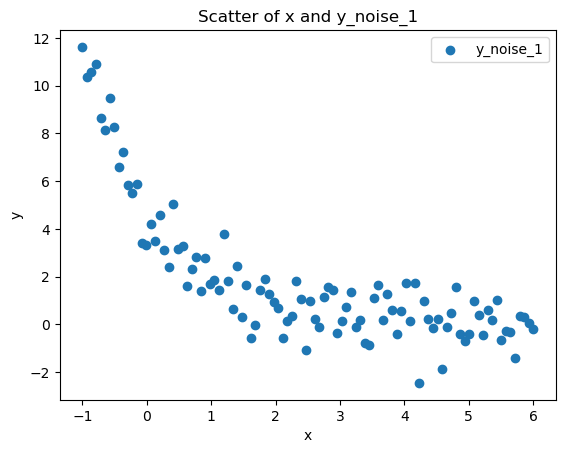

In [195]:
plt.figure()

plt.scatter(x, y1, label = "y_noise_1")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Scatter of x and y_noise_1")
plt.legend()

plt.show()

In [196]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [197]:
p0 = [1, 1]

popt, pcov = curve_fit(model, x, y1, p0 = p0)
A_fit, k_fit = popt

f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)"

'Fit: y = 4.71 * e^(-0.92 * x)'

In [198]:
residuals = y1 - model(x, A_fit, k_fit)
weighted_residuals = residuals / np.std(y1)    
chi2 = np.sum(weighted_residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

print(chi2)
print(chi2_reduced)

9.039685776738809
0.0922416915993756


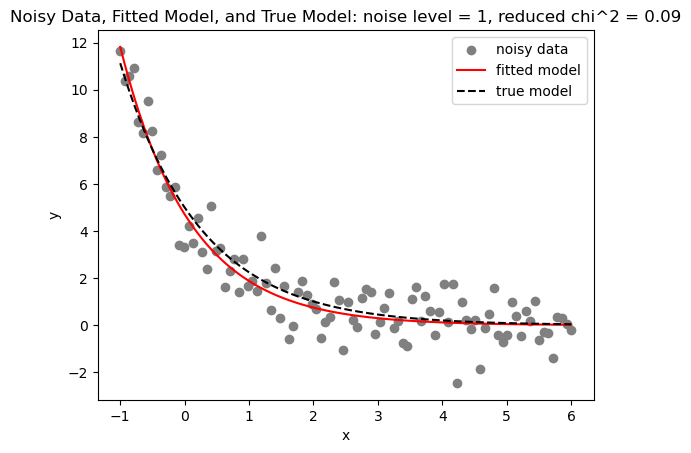

In [199]:
plt.figure()

plt.scatter(x, y1, color = "gray", label = "noisy data")
plt.plot(x, model(x, 4.71, 0.92), color = "red", label = "fitted model")
plt.plot(x, model(x, 5, 0.8), color = "black", ls = "--", label = "true model")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noisy Data, Fitted Model, and True Model: noise level = 1, reduced chi^2 = {chi2_reduced:.2f}")
plt.legend()

plt.show()

In [200]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0 = p0, sigma = np.std(y), absolute_sigma = True)
    A_fit, k_fit = popt
    
    residuals = y - model(x, A_fit, k_fit)
    weighted_residuals = residuals / np.std(y)
    chi2 = np.sum(weighted_residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    
    return (A_fit, k_fit, chi2_reduced)

In [201]:
print(df.columns)

Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'], dtype='object')


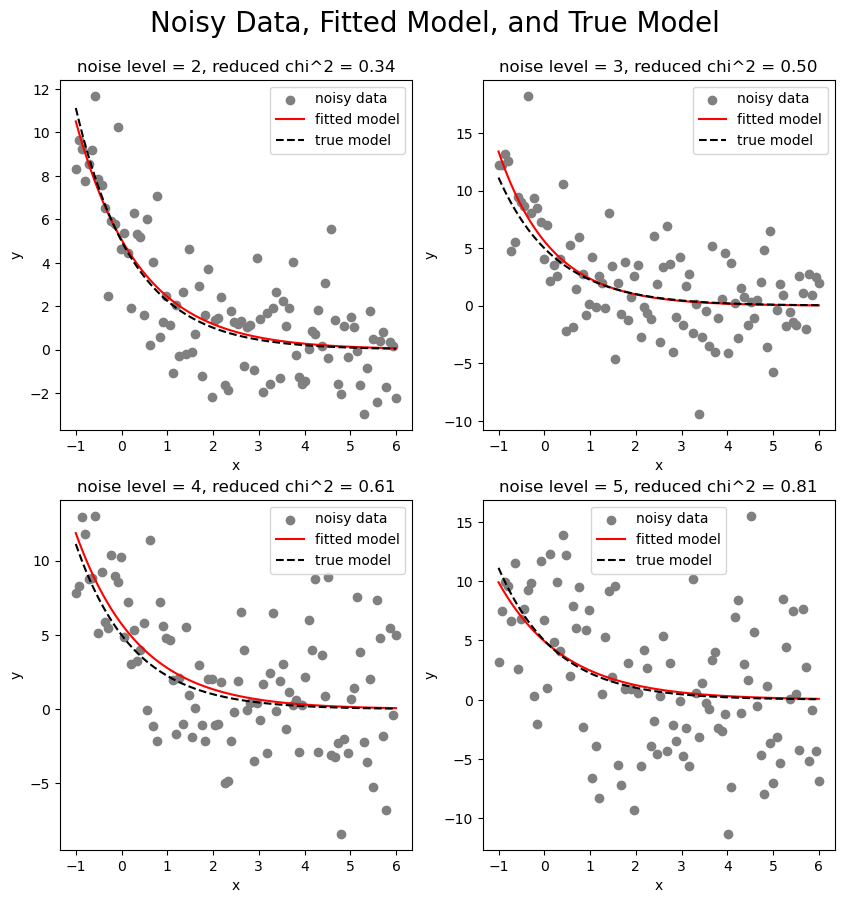

In [202]:
fig, axes = plt.subplots(2, 2, figsize = (10, 10))
flat_ax = axes.flatten()

for index, column in enumerate(df.columns[2:]):
    A_fit, k_fit, chi2_reduced = fit_model(x, df[column])
    flat_ax[index].scatter(x, df[column], color = "gray", label = "noisy data")
    flat_ax[index].plot(x, A_fit * (np.e ** (-k_fit * x)), color = "red", label = "fitted model")
    flat_ax[index].plot(x, model(x, 5, 0.8), color = "black", ls = "--", label = "true model")

    flat_ax[index].set_xlabel("x")
    flat_ax[index].set_ylabel("y")
    flat_ax[index].set_title(f"noise level = {index + 2}, reduced chi^2 = {chi2_reduced:.2f}")
    flat_ax[index].legend()

fig.suptitle("Noisy Data, Fitted Model, and True Model", fontsize = 20, y = 0.95) 

plt.show()

In [203]:
# As the noise level increases, the red and black dotted lines are less aligned. 
# As the noise level increases, the reduced chi^2 increases. 

In [204]:
A_fit = []
k_fit = []
chi2_reduced = []

for n in [1, 2, 3, 4, 5]:
    A_fit_n, k_fit_n, chi2_reduced_n = fit_model(df["x"], df[f"y_noise_{n}"])
    A_fit_n = float(A_fit_n)
    k_fit_n = float(k_fit_n)
    chi2_reduced_n = float(chi2_reduced_n)
    A_fit.append(A_fit_n)
    k_fit.append(k_fit_n)    
    chi2_reduced.append(chi2_reduced_n)

In [205]:
para_df = pd.DataFrame()
para_df["Noise level"] = [1, 2, 3, 4, 5]
para_df["A fit"] = A_fit
para_df["K fit"] = k_fit
para_df["Reduced chi-squared"] = chi2_reduced
para_df

,Noise level,A fit,K fit,Reduced chi-squared
0,1,4.714814,0.918308,0.092242
1,2,5.063889,0.730396,0.344627
2,3,5.609396,0.870372,0.500382
3,4,5.738727,0.725965,0.606483
4,5,4.943458,0.695012,0.805397


In [206]:
para_df.to_csv("noisy_parameters.csv", index = False)